# 01 · Transaction simulator and exploratory analysis

Kronos has never needed fraud labels, so there is no real labelled dataset. This notebook
shows the **schema-faithful synthetic log** produced by `kronos_ml.simulator`:

* users with a home planet, activity level, contact circle and active hours,
* normal transfers (repeat contacts, log-normal amounts, daytime, weekend / payday peaks),
* packet physics from the real Go engine constants (distance, flight time, black-hole outcome),
* six injected abuse patterns, labelled **only for evaluation**.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kronos_ml.config import load_config, DATA_DIR, MODELS_DIR, REPORT_DIR
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
cfg = load_config()

In [2]:
tx = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["created_at"])
users = pd.read_csv(DATA_DIR / "users.csv", parse_dates=["created_at"])
print(f"{len(tx):,} transfers, {len(users):,} users, {tx.created_at.min():%Y-%m-%d} → {tx.created_at.max():%Y-%m-%d}")
print(f"fraud rate {tx.is_fraud.mean():.2%}")
tx.head()

172,932 transfers, 2,086 users, 2026-01-01 → 2026-03-31
fraud rate 2.04%


,tx_id,sender_id,receiver_id,amount,currency_id,origin_planet,destination_planet,created_at,status,distance,travel_time_s,min_bh_dist,min_dilation,outcome,sender_balance,is_fraud,fraud_type,fraud_instance
0,b86a75da-99ad-44d2-8fe0-79c3fdef55db,0029c96e-ef91-469e-91ab-47a026601b20,f78bfb5d-f1a9-4b1a-b8c6-0c7fc34cb1dd,16.39,EARTH,earth,mars,2026-01-01 06:00:00.111238718,settled,239.452,5.404,50.715,0.675,settled,1400.0,0,none,-1
1,61855c0a-ed22-4176-ab1d-01da626c315d,ad6f18ca-7936-46cc-9116-d2588ea36e91,5a9a7bea-ef6a-478a-b5b7-8bcd43d72fcb,37.62,MERCURY,mercury,mercury,2026-01-01 06:00:00.364743233,settled,0.000,0.000,131.772,1.000,settled,1400.0,0,none,-1
2,d0c1cabd-be20-44bb-83a9-7fb424164f82,ffb900ef-d740-48c3-bcc7-9cd6298f75c9,786f91ed-5db5-447d-ae08-45b60a4cbb3c,26.88,MARS,mars,earth,2026-01-01 06:00:01.393841028,settled,227.761,4.555,129.342,1.000,settled,1400.0,0,none,-1
3,0162dc2d-9b4a-4e5d-8b72-46dec0bd1ce7,3d334519-1236-40c3-863e-4829edd2ff15,6404316e-577b-4fa4-aa12-ba684c9e472d,50.57,VENUS,venus,venus,2026-01-01 06:00:01.404917240,settled,0.000,0.000,156.956,1.000,settled,1400.0,0,none,-1
4,11d0ba16-fb74-4956-98ef-b40cf0e7b011,25a2404a-a630-4db7-8e55-0d54865091ca,dec5be0b-d8c8-4bd7-a425-2910742f97c9,67.35,MARS,mars,mars,2026-01-01 06:00:02.427239418,settled,0.000,0.000,140.476,1.000,settled,1400.0,0,none,-1


Columns mirror the `transactions` table in `backend/internal/db/schema_enhanced.sql`; the extra physics fields come from a vectorised port of `physics.go`.

In [3]:
summary = tx.groupby("fraud_type").agg(rows=("tx_id", "size"), instances=("fraud_instance", "nunique"),
                                       median_amount=("amount", "median"), destroyed=("outcome", lambda s: (s == "destroyed").mean()))
summary["share"] = summary["rows"] / len(tx)
summary.sort_values("rows", ascending=False).round(3)

,rows,instances,median_amount,destroyed,share
fraud_type,,,,,
none,169408,1,21.800,0.150,0.980
micro_drain,699,23,12.580,0.169,0.004
layering,698,200,120.155,0.173,0.004
mule_fan_in,587,39,48.550,0.165,0.003
odd_hour_spike,581,125,50.820,0.158,0.003
whale,533,533,628.120,0.150,0.003
new_account_burst,426,47,96.830,0.188,0.002


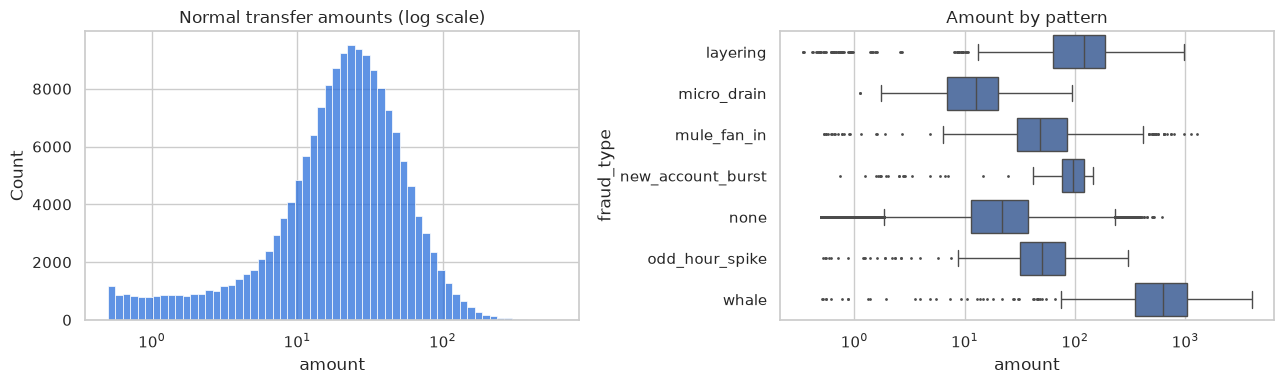

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=tx[tx.is_fraud == 0], x="amount", log_scale=True, bins=60, ax=ax[0], color="#2a6fdb")
ax[0].set_title("Normal transfer amounts (log scale)")
sns.boxplot(data=tx, y="fraud_type", x="amount", log_scale=True, ax=ax[1], order=summary.index, fliersize=1)
ax[1].set_title("Amount by pattern")
plt.tight_layout()

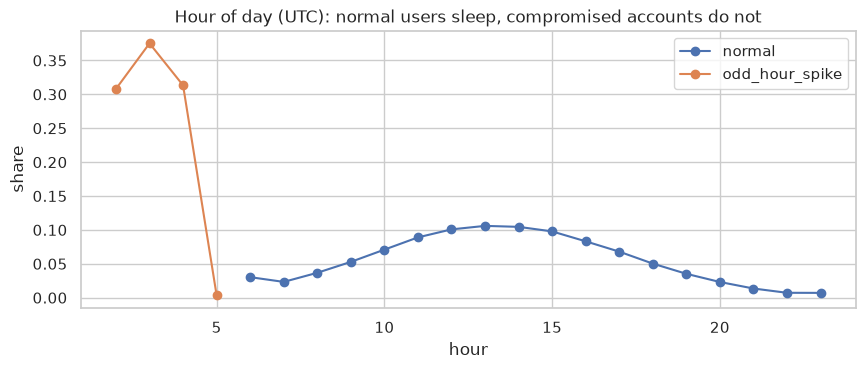

In [5]:
tx["hour"] = tx.created_at.dt.hour
fig, ax = plt.subplots(figsize=(10, 3.6))
for label, d in [("normal", tx[tx.is_fraud == 0]), ("odd_hour_spike", tx[tx.fraud_type == "odd_hour_spike"])]:
    d.hour.value_counts(normalize=True).sort_index().plot(ax=ax, marker="o", label=label)
ax.set(title="Hour of day (UTC): normal users sleep, compromised accounts do not", xlabel="hour", ylabel="share")
ax.legend();

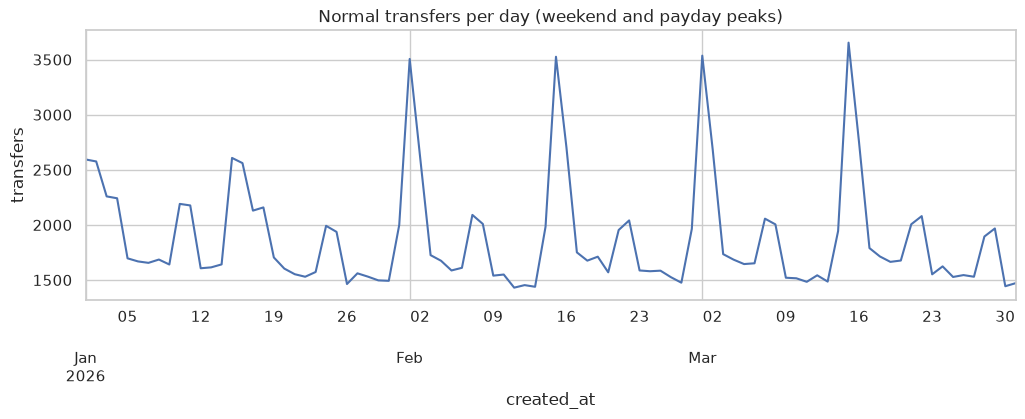

In [6]:
daily = tx[tx.is_fraud == 0].set_index("created_at").resample("D").size()
ax = daily.plot(figsize=(12, 3.5), title="Normal transfers per day (weekend and payday peaks)")
ax.set_ylabel("transfers");

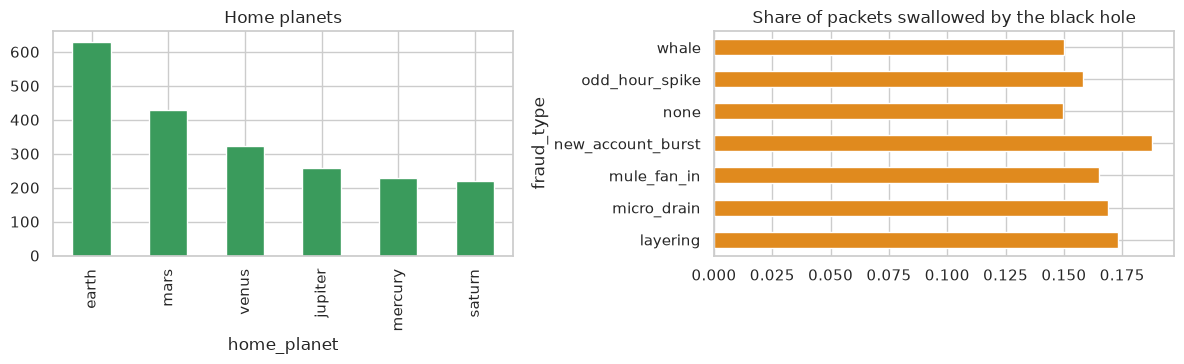

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
users.home_planet.value_counts().plot.bar(ax=ax[0], title="Home planets", color="#3a9b5c")
tx.groupby("fraud_type")["outcome"].apply(lambda s: (s == "destroyed").mean()).plot.barh(ax=ax[1], color="#e08a1e",
    title="Share of packets swallowed by the black hole")
plt.tight_layout()

### One example of each pattern

In [8]:
cols = ["created_at", "sender_id", "receiver_id", "amount", "sender_balance", "fraud_type"]
for pattern in ["micro_drain", "whale", "odd_hour_spike", "layering", "mule_fan_in", "new_account_burst"]:
    inst = tx[tx.fraud_type == pattern].fraud_instance.iloc[0]
    ex = tx[tx.fraud_instance == inst][cols].copy()
    ex["sender_id"] = ex.sender_id.str[:8]; ex["receiver_id"] = ex.receiver_id.str[:8]
    print(f"\n=== {pattern}: {len(ex)} transfers ===")
    print(ex.head(6).to_string(index=False))


=== micro_drain: 52 transfers ===
                   created_at sender_id receiver_id  amount  sender_balance  fraud_type
2026-01-05 00:54:59.315811396  f973e345    dc6e2e2b   34.88         1400.00 micro_drain
2026-01-05 00:55:00.099297762  f973e345    f47d0f30   32.29         1365.12 micro_drain
2026-01-05 00:55:04.664667130  f973e345    e44018ff   12.45         1332.83 micro_drain
2026-01-05 00:55:09.628825903  f973e345    6a425416   18.35         1320.38 micro_drain
2026-01-05 00:56:20.107765198  f973e345    f9387e44   35.33         1302.03 micro_drain
2026-01-05 00:56:46.689346313  f973e345    30a9c3aa   42.94         1266.70 micro_drain

=== whale: 1 transfers ===
                   created_at sender_id receiver_id  amount  sender_balance fraud_type
2026-01-04 08:56:08.191543341  87ce1562    b6c8ac2b  580.96         1570.36      whale

=== odd_hour_spike: 8 transfers ===
                   created_at sender_id receiver_id  amount  sender_balance     fraud_type
2026-01-04 02:43:58

**Takeaways.** Normal behaviour is regular (contacts, amounts, hours). Each fraud pattern breaks
a *different* regularity: amount (whale), speed and fan-out (micro-drain), time of day (odd-hour),
account age (new-account burst, mule) and money flow structure (layering, mule). A single rule cannot
cover them all, which motivates multivariate anomaly detection.